# Search-5b : Natural Evolution Strategies (NES)

**Navigation** : [<< Search-5 Algorithmes génétiques](Search-05-GeneticAlgorithms.ipynb) | [Index](../README.md) | [CSP-1 Fundamentals >>](../Part2-CSP/CSP-1-Fundamentals.ipynb)

Le carnet Search-5 faisait évoluer une **population** d'individus. Une stratégie d'évolution naturelle (NES) fait évoluer une **distribution** : on tire des points d'une gaussienne, on les classe, puis on déplace la gaussienne par un pas de gradient sur ses propres paramètres. Le carnet suit l'article de référence et confronte ses affirmations à des mesures :

> D. Wierstra, T. Schaul, T. Glasmachers, Y. Sun, J. Peters, J. Schmidhuber, « Natural Evolution Strategies », *Journal of Machine Learning Research* 15 (2014), p. 949-980.

Copie lue intégralement : `G:\Mon Drive\MyIA\IA\Bibliographie IA\MachineLearning\2014 - Wierstra et al - Natural Evolution Strategies.pdf` (sha256 préfixe `80ec8495`, hors dépôt).

## Objectifs d'apprentissage

À la fin de ce carnet, vous saurez :
1. **Dériver** le gradient de recherche par l'astuce de la log-vraisemblance (§2 de l'article).
2. **Expliquer** pourquoi le gradient simple est instable et ce que le gradient naturel corrige (§2.2-2.3).
3. **Implémenter** xNES (covariance pleine) et SNES (diagonale) avec les réglages par défaut de la table 1.
4. **Mesurer** l'invariance par rotation qui distingue xNES de SNES, et situer les deux face à CMA-ES.
5. **Vérifier** numériquement le lien au premier ordre entre la mise à jour xNES et le rang-μ de CMA-ES (§4).

### Prérequis
- Search-5 (algorithmes génétiques) et Search-4 (recherche locale).
- Python 3.10+, numpy, scipy, matplotlib, et la bibliothèque `cma` (référence CMA-ES de N. Hansen, `pip install cma`).

### Durée estimée : 50 minutes

## 1. Mise en place

Tout le carnet tourne sur CPU. Les graines utilisées pour les comparaisons sont `{0, 1, 7, 42}`, et chaque comparaison rapporte la médiane, le minimum et le maximum sur ces quatre tirages.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
import cma

SEEDS = (0, 1, 7, 42)
np.set_printoptions(precision=4, suppress=False)
print("numpy", np.__version__, "| cma", cma.__version__)

numpy 2.4.6 | cma 4.5.0


## 2. Le gradient de recherche (§2)

On cherche à **maximiser l'espérance de la fitness** sous une distribution de recherche $\pi(z\mid\theta)$ :

$$J(\theta) = \mathbb{E}_\theta[f(z)] = \int f(z)\,\pi(z\mid\theta)\,dz .$$

L'astuce de la log-vraisemblance donne $\nabla_\theta J = \mathbb{E}_\theta[f(z)\,\nabla_\theta \log\pi(z\mid\theta)]$, que l'on estime sur $\lambda$ échantillons. Pour une gaussienne à une dimension $\theta=(\mu,\sigma)$, l'article écrit les deux composantes :

$$\nabla_\mu J \approx \frac{1}{\lambda}\sum_k f(z_k)\,\frac{z_k-\mu}{\sigma^2}, \qquad \nabla_\sigma J \approx \frac{1}{\lambda}\sum_k f(z_k)\,\frac{(z_k-\mu)^2-\sigma^2}{\sigma^3}.$$

Le §2.2 avance que cette mise à jour **ne sait pas localiser un optimum quadratique** : le pas sur $\mu$ et sur $\sigma$ est proportionnel à $1/\sigma$, donc plus la distribution se resserre sur l'optimum, plus le pas devient grand et instable. La figure 1 de l'article le montre sur $f(z)=z^2$ avec $\lambda=10$ et $\eta=0{,}01$. On rejoue cette expérience sur 300 tirages, en partant de $\mu=1$, $\sigma=1$ (l'article ne donne pas le point de départ ; c'est notre choix). Un tirage est compté **en échec** dès que $\sigma$ devient négatif ou non fini.

In [2]:
def gradient_simple(graine, generations=1000, lam=10, eta=0.01, mu=1.0, sigma=1.0):
    # Algorithme 2 de l'article, a une dimension, fitness brute f = -z^2 (maximisee).
    rng = np.random.default_rng(graine)
    mus, sigmas = np.full(generations, np.nan), np.full(generations, np.nan)
    for g in range(generations):
        z = mu + sigma * rng.standard_normal(lam)
        fz = -z ** 2
        g_mu = np.mean(fz * (z - mu) / sigma ** 2)
        g_sigma = np.mean(fz * ((z - mu) ** 2 - sigma ** 2) / sigma ** 3)
        mu, sigma = mu + eta * g_mu, sigma + eta * g_sigma
        if not np.isfinite(sigma) or sigma <= 0:
            break  # la distribution n'existe plus : echec
        mus[g], sigmas[g] = abs(mu), sigma
    return mus, sigmas

t0 = time.time()
runs = [gradient_simple(s) for s in range(300)]
M = np.array([r[0] for r in runs]); S = np.array([r[1] for r in runs])
print(f"300 tirages en {time.time() - t0:.1f} s")
print(f"{'generation':>10} | {'echecs cumules':>14} | {'mediane |mu| (survivants)':>26} | {'mediane sigma':>13}")
for g in (0, 10, 100, 300, 600, 999):
    echecs = int(np.isnan(S[:, g]).sum())
    print(f"{g:>10} | {echecs:>14} | {np.nanmedian(M[:, g]):>26.3e} | {np.nanmedian(S[:, g]):>13.3e}")

300 tirages en 13.0 s
generation | echecs cumules |  mediane |mu| (survivants) | mediane sigma
         0 |              0 |                  9.811e-01 |     9.921e-01
        10 |              0 |                  8.031e-01 |     8.148e-01
       100 |              0 |                  1.281e-01 |     1.257e-01
       300 |              9 |                  2.183e-03 |     2.062e-03
       600 |             44 |                  5.227e-06 |     5.512e-06
       999 |             80 |                  1.728e-09 |     1.896e-09


### Lecture du résultat

Aucun tirage n'échoue pendant les cent premières générations, mais les échecs s'accumulent ensuite : 9 tirages sur 300 à la génération 300, 44 à la génération 600, et 80 à la génération 999, soit **27 %** des tirages dont la distribution a cessé d'exister. Le mécanisme est celui que décrit le §2.2 : le pas sur $\sigma$ est proportionnel à $1/\sigma$, et plus $\sigma$ se resserre, plus un seul tirage malchanceux suffit à le rendre négatif.

Les survivants, eux, convergent : $|\mu|$ médian passe de 0,98 à $1{,}7\times10^{-9}$ en 1000 générations, soit environ une décade toutes les 110 générations. C'est une **reproduction partielle** de la figure 1. L'article montre une distribution incapable de se fixer sur l'optimum ; ici la médiane des survivants y arrive lentement, et le défaut se lit plutôt dans le **taux d'échec croissant**. L'écart peut tenir au point de départ, que l'article ne donne pas.

## 3. Le gradient naturel (§2.3) et la mise en forme de la fitness (§3.1)

Le gradient naturel remplace la distance euclidienne entre paramètres par la divergence de Kullback-Leibler entre distributions : $\tilde\nabla_\theta J = F^{-1}\nabla_\theta J$, où $F$ est la matrice d'information de Fisher. Pour une gaussienne, l'article montre (§3.3-3.4) qu'en **coordonnées locales naturelles** ($z = \mu + \sigma B^\top s$, $s\sim\mathcal N(0,I)$) la matrice de Fisher est l'identité : le gradient simple dans ces coordonnées **est** le gradient naturel. Les pas deviennent alors des multiplications sur $\sigma$, ce qui supprime le facteur $1/\sigma$.

Deuxième ingrédient : on ne pondère plus les échantillons par leur fitness brute, mais par une **utilité qui ne dépend que du rang** (§3.1) :

$$u_k = \frac{\max\big(0,\ \log(\tfrac{\lambda}{2}+1) - \log k\big)}{\sum_{j=1}^{\lambda} \max\big(0,\ \log(\tfrac{\lambda}{2}+1) - \log j\big)} - \frac{1}{\lambda}.$$

La cellule suivante définit ces utilités, les réglages par défaut de la table 1, puis les deux algorithmes du papier : **xNES** (algorithme 5, covariance pleine) et **SNES** (algorithme 6, covariance diagonale). On minimise $f$ partout : trier par $f$ croissant revient à maximiser $-f$.

In [3]:
def utilites(lam):
    k = np.arange(1, lam + 1)
    brut = np.maximum(0.0, np.log(lam / 2 + 1) - np.log(k))
    return brut / brut.sum() - 1.0 / lam

def reglages_table1(d):
    lam = 4 + int(np.floor(3 * np.log(d)))
    eta_sigma_xnes = (9 + 3 * np.log(d)) / (5 * d * np.sqrt(d))  # eta_sigma = eta_B
    eta_sigma_snes = (3 + np.log(d)) / (5 * np.sqrt(d))
    return lam, eta_sigma_xnes, eta_sigma_snes

def xnes(f, mu, sigma, budget, cible, graine, lam=None, utilite=None):
    # Algorithme 5 : xNES, eta_mu = 1, eta_sigma = eta_B (table 1).
    d = len(mu); rng = np.random.default_rng(graine)
    lam0, eta, _ = reglages_table1(d); lam = lam or lam0
    u = utilite(lam) if utilite else utilites(lam)
    mu = np.array(mu, float); B = np.eye(d); evals = 0; trace = []
    while evals < budget:
        s = rng.standard_normal((lam, d))
        z = mu + sigma * s @ B.T
        fz = np.array([f(x) for x in z]); evals += lam
        ordre = np.argsort(fz); s = s[ordre]; meilleur = fz[ordre[0]]
        trace.append((evals, meilleur))
        if meilleur <= cible:
            break
        g_delta = u @ s
        g_M = (s.T * u) @ s - u.sum() * np.eye(d)
        g_sigma = np.trace(g_M) / d
        g_B = g_M - g_sigma * np.eye(d)
        mu = mu + sigma * B @ g_delta
        sigma = sigma * np.exp(eta / 2 * g_sigma)
        B = B @ expm(eta / 2 * g_B)
    return evals, meilleur, np.array(trace)

def snes(f, mu, sigma, budget, cible, graine):
    # Algorithme 6 : SNES, covariance diagonale, eta_mu = 1.
    d = len(mu); rng = np.random.default_rng(graine)
    lam, _, eta = reglages_table1(d); u = utilites(lam)
    mu = np.array(mu, float); sig = np.full(d, float(sigma)); evals = 0; trace = []
    while evals < budget:
        s = rng.standard_normal((lam, d))
        z = mu + sig * s
        fz = np.array([f(x) for x in z]); evals += lam
        ordre = np.argsort(fz); s = s[ordre]; meilleur = fz[ordre[0]]
        trace.append((evals, meilleur))
        if meilleur <= cible:
            break
        mu = mu + sig * (u @ s)
        sig = sig * np.exp(eta / 2 * (u @ (s ** 2 - 1)))
    return evals, meilleur, np.array(trace)

u10 = utilites(10)
print("utilites lambda=10 :", np.round(u10, 4), "| somme =", f"{u10.sum():.1e}")
print(f"{'d':>3} | {'lambda':>6} | {'eta_sigma=eta_B (xNES)':>22} | {'eta_sigma (SNES)':>16}")
for d in (1, 2, 5, 10, 20, 40):
    lam, ex, es = reglages_table1(d)
    print(f"{d:>3} | {lam:>6} | {ex:>22.4f} | {es:>16.4f}")

utilites lambda=10 : [ 0.3295  0.1634  0.0662 -0.0028 -0.0563 -0.1    -0.1    -0.1    -0.1
 -0.1   ] | somme = -5.6e-17
  d | lambda | eta_sigma=eta_B (xNES) | eta_sigma (SNES)
  1 |      4 |                 1.8000 |           0.6000
  2 |      6 |                 0.7834 |           0.5223
  5 |      8 |                 0.2474 |           0.4123
 10 |     10 |                 0.1006 |           0.3354
 20 |     12 |                 0.0402 |           0.2681
 40 |     15 |                 0.0159 |           0.2115


### Lecture du résultat

Les utilités somment à zéro, à l'arrondi machine près ($-5{,}6\times10^{-17}$). Seuls les trois meilleurs échantillons reçoivent un poids positif (0,330, 0,163, 0,066). Toute la moitié inférieure reçoit le même poids, $-1/\lambda = -0{,}1$ : être le pire ou le sixième ne change rien. La mise à jour ne voit donc **ni l'amplitude de $f$ ni l'ordre interne de la mauvaise moitié**.

La table 1 règle les pas de façon très différente pour les deux algorithmes. Le pas de xNES décroît en $d^{-3/2}$ : 1,80 à $d=1$, 0,0159 à $d=40$. Celui de SNES décroît en $d^{-1/2}$ : 0,60 à $d=1$, 0,21 à $d=40$. La raison est que xNES doit estimer $d(d+1)/2$ paramètres de covariance, et SNES seulement $d$. La population, elle, ne croît qu'en logarithme : 4 individus à $d=1$, 15 à $d=40$.

### 3.1 Le même problème à une dimension, avec le gradient naturel

On reprend $f(z)=z^2$, le même départ $\mu=1$, $\sigma=1$, et les mêmes 300 graines. Seules changent la mise à jour (SNES à $d=1$, donc gradient naturel et pas multiplicatif sur $\sigma$) et la population ($\lambda=10$, comme ci-dessus, au lieu du défaut de la table 1).

generation | echecs | mediane |mu| | mediane sigma
         0 |      0 |    1.946e-01 |     9.803e-01
        10 |      0 |    2.699e-02 |     9.926e-02
        50 |      0 |    2.216e-06 |     1.176e-05
       100 |      0 |    3.232e-11 |     1.310e-10
       199 |      0 |    5.286e-21 |     2.404e-20


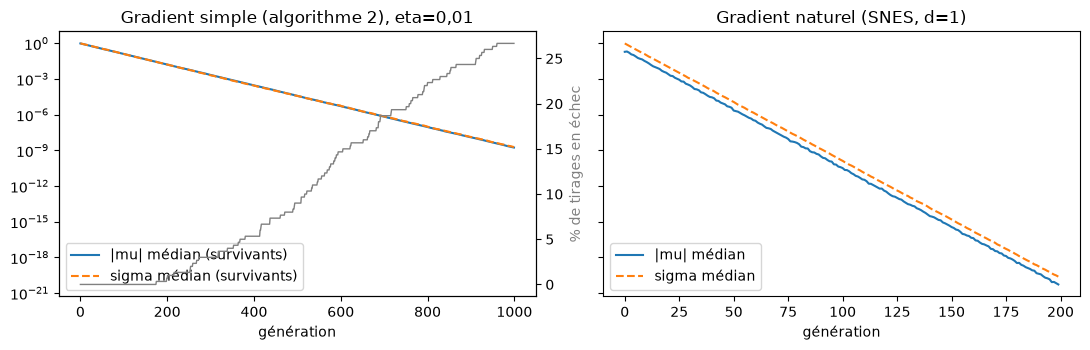

In [4]:
def naturel_1d(graine, generations=200, lam=10, mu=1.0, sigma=1.0):
    rng = np.random.default_rng(graine)
    u = utilites(lam); eta = reglages_table1(1)[2]
    sortie = np.empty((generations, 2))
    for g in range(generations):
        s = rng.standard_normal(lam); z = mu + sigma * s
        s = s[np.argsort(z ** 2)]
        mu = mu + sigma * (u @ s)
        sigma = sigma * np.exp(eta / 2 * (u @ (s ** 2 - 1)))
        sortie[g] = abs(mu), sigma
    return sortie

N = np.array([naturel_1d(s) for s in range(300)])
print(f"{'generation':>10} | {'echecs':>6} | {'mediane |mu|':>12} | {'mediane sigma':>13}")
for g in (0, 10, 50, 100, 199):
    echecs = int((~np.isfinite(N[:, g, 1]) | (N[:, g, 1] <= 0)).sum())
    print(f"{g:>10} | {echecs:>6} | {np.median(N[:, g, 0]):>12.3e} | {np.median(N[:, g, 1]):>13.3e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
ax[0].semilogy(np.nanmedian(M, axis=0), label="|mu| médian (survivants)")
ax[0].semilogy(np.nanmedian(S, axis=0), "--", label="sigma médian (survivants)")
ax0b = ax[0].twinx(); ax0b.plot(np.isnan(S).mean(axis=0) * 100, color="grey", lw=1)
ax0b.set_ylabel("% de tirages en échec", color="grey")
ax[0].set_title("Gradient simple (algorithme 2), eta=0,01")
ax[1].semilogy(np.median(N[:, :, 0], axis=0), label="|mu| médian")
ax[1].semilogy(np.median(N[:, :, 1], axis=0), "--", label="sigma médian")
ax[1].set_title("Gradient naturel (SNES, d=1)")
for a in ax:
    a.set_xlabel("génération"); a.legend(loc="lower left")
plt.tight_layout(); plt.show()

### Lecture du résultat

On reste sur le même problème, avec la même population de 10 et les mêmes 300 graines. Cette fois, **aucun tirage n'échoue**. $|\mu|$ médian vaut $2{,}2\times10^{-6}$ à la génération 50, $3{,}2\times10^{-11}$ à la génération 100, et $5{,}3\times10^{-21}$ à la génération 199. Cela fait une décade environ toutes les 10 générations, contre une toutes les 110 pour les survivants du gradient simple. Sur la figure, $\sigma$ décroît parallèlement à $|\mu|$ : la distribution se resserre au rythme où elle s'approche de l'optimum, ce qui est le comportement souhaité.

La comparaison n'est pas « à pas égal ». Le gradient naturel prend ici $\eta_\mu = 1$ et $\eta_\sigma = 0{,}6$, contre 0,01 pour le gradient simple. C'est précisément l'apport mesuré : la paramétrisation naturelle, avec un pas multiplicatif sur $\sigma$, **supporte des pas soixante à cent fois plus grands sans faire exploser la distribution**. Le gradient simple, au contraire, échoue déjà en partie avec $\eta=0{,}01$.

### 3.2 Invariance par transformation monotone de la fitness

Puisque seules les **positions dans le classement** entrent dans la mise à jour, toute transformation strictement croissante de $f$ doit produire **exactement la même trajectoire** à graine égale. On le vérifie sur un ellipsoïde à trois dimensions, en comparant $f$ et $g = \log(1+f)^3$. Le gradient simple, qui pondère par $f$ brute, n'a pas cette propriété : on le montre sur le cas 1-D en remplaçant $-z^2$ par $-\log(1+z^2)$.

In [5]:
f3 = lambda x: float(np.sum(np.arange(1, 4) * x ** 2))
g3 = lambda x: np.log1p(f3(x)) ** 3
_, _, ta = xnes(f3, np.ones(3), 1.0, 900, -1.0, graine=5)
_, _, tb = xnes(g3, np.ones(3), 1.0, 900, -1.0, graine=5)
retour = np.expm1(np.cbrt(tb[:, 1]))  # on ramene g dans l'echelle de f
print("xNES : evaluations comparees :", len(ta), "generations de part et d'autre")
print("ecart relatif max entre f(trajectoire sur f) et f(trajectoire sur g) :",
      f"{np.max(np.abs(ta[:, 1] - retour) / ta[:, 1]):.2e}")
print("meilleur f apres 900 evaluations :", f"{ta[-1, 1]:.3e}")

def gradient_simple_transf(graine, transf, generations=300, lam=10, eta=0.01):
    rng = np.random.default_rng(graine); mu, sigma = 1.0, 1.0
    for _ in range(generations):
        z = mu + sigma * rng.standard_normal(lam); fz = -transf(z ** 2)
        mu, sigma = (mu + eta * np.mean(fz * (z - mu) / sigma ** 2),
                     sigma + eta * np.mean(fz * ((z - mu) ** 2 - sigma ** 2) / sigma ** 3))
        if not np.isfinite(sigma) or sigma <= 0:
            return np.nan
    return abs(mu)
brut = [gradient_simple_transf(s, lambda v: v) for s in range(5)]
logt = [gradient_simple_transf(s, np.log1p) for s in range(5)]
print("gradient simple, |mu| apres 300 generations, f brute   :", np.round(brut, 6))
print("gradient simple, |mu| apres 300 generations, log(1+f)  :", np.round(logt, 6))

xNES : evaluations comparees : 129 generations de part et d'autre
ecart relatif max entre f(trajectoire sur f) et f(trajectoire sur g) : 3.41e-16
meilleur f apres 900 evaluations : 7.957e-13
gradient simple, |mu| apres 300 generations, f brute   : [0.0035 0.0025 0.003  0.0017 0.0029]
gradient simple, |mu| apres 300 generations, log(1+f)  : [0.0194 0.014  0.0189 0.0099 0.0147]


### Lecture du résultat

Côté xNES, les deux exécutions durent 129 générations. Leurs trajectoires coïncident à $3{,}4\times10^{-16}$ près en écart relatif, c'est-à-dire **à la précision machine** : remplacer $f$ par $\log(1+f)^3$ ne change pas un seul échantillon. Le meilleur $f$ atteint $8\times10^{-13}$ en 900 évaluations sur cet ellipsoïde en dimension 3.

Côté gradient simple, mêmes graines, la transformation change le résultat : après 300 générations, $|\mu|$ est entre 0,0017 et 0,0035 avec $f$ brute, et entre 0,0099 et 0,0194 avec $\log(1+f)$. La compression logarithmique écrase les écarts de fitness, donc les poids, donc le pas. L'algorithme converge alors environ **cinq à six fois moins loin** dans le même temps. C'est ce que le §3.1 annonce : la mise en forme par les rangs rend l'algorithme indifférent à toute **reparamétrisation monotone** de l'objectif, que le gradient simple subit.

## 4. Le banc décisif : rotation (§5.3)

xNES adapte une matrice $B$ pleine : sa distribution peut s'aligner sur n'importe quelle direction. SNES ne règle que des écarts-types **par coordonnée** : il ne peut s'étirer que le long des axes. L'article l'énonce au §5.3 : SNES devrait faire au moins aussi bien que xNES sur un problème **séparable**, et nettement moins bien quand les variables sont fortement dépendantes.

Le banc qui tranche est un ellipsoïde mal conditionné en dimension $d=10$, rapport d'échelle $10^6$ entre les axes extrêmes :

$$f(x)=\sum_{i=1}^{d} 10^{6\frac{i-1}{d-1}}\,x_i^2,$$

une fois tel quel, une fois **après une rotation aléatoire fixe** $x\mapsto Rx$. La rotation ne change ni l'optimum ni le conditionnement ; elle rend seulement les variables dépendantes. Cible $f\le 10^{-8}$ (celle des figures 5 et 6), départ $x_0=(3,\dots,3)$, $\sigma_0=1$, budget de 40 000 évaluations. Troisième concurrent : **CMA-ES** dans l'implémentation de référence `cma` (N. Hansen), avec les mêmes $x_0$, $\sigma_0$, cible et budget.

In [6]:
D = 10
COND = 10 ** (6 * np.arange(D) / (D - 1))
ellipsoide = lambda x: float(COND @ x ** 2)
R = np.linalg.qr(np.random.default_rng(2014).standard_normal((D, D)))[0]
ellipsoide_tourne = lambda x: ellipsoide(R @ x)
X0, SIGMA0, CIBLE, BUDGET = np.full(D, 3.0), 1.0, 1e-8, 40_000

def lancer_cma(f, graine):
    es = cma.CMAEvolutionStrategy(X0, SIGMA0, {"seed": graine + 1, "ftarget": CIBLE,
                                              "maxfevals": BUDGET, "verbose": -9})
    trace = []
    while not es.stop():
        X = es.ask(); F = [f(x) for x in X]; es.tell(X, F)
        trace.append((es.countevals, min(F)))
    return es.countevals, es.result.fbest, np.array(trace)

resultats, traces = {}, {}
t0 = time.time()
for nom_f, f in (("ellipsoide", ellipsoide), ("ellipsoide tourne", ellipsoide_tourne)):
    for nom_a, algo in (("xNES", lambda f, s: xnes(f, X0, SIGMA0, BUDGET, CIBLE, s)),
                        ("SNES", lambda f, s: snes(f, X0, SIGMA0, BUDGET, CIBLE, s)),
                        ("CMA-ES", lancer_cma)):
        sorties = [algo(f, s) for s in SEEDS]
        resultats[nom_f, nom_a] = [(e, b) for e, b, _ in sorties]
        traces[nom_f, nom_a] = sorties[0][2]
print(f"banc complet en {time.time() - t0:.1f} s\n")
print(f"{'probleme':<18} | {'algo':<6} | {'atteint':>7} | {'evals mediane':>13} | {'min-max':>13} | {'f final max':>11}")
for (nom_f, nom_a), r in resultats.items():
    e = np.array([x[0] for x in r]); b = np.array([x[1] for x in r])
    ok = int((b <= CIBLE).sum())
    print(f"{nom_f:<18} | {nom_a:<6} | {ok:>5}/4 | {np.median(e):>13.0f} | {e.min():>6}-{e.max():<6} | {b.max():>11.2e}")

banc complet en 8.2 s

probleme           | algo   | atteint | evals mediane |       min-max | f final max
ellipsoide         | xNES   |     4/4 |          8850 |   8690-9010   |    9.87e-09
ellipsoide         | SNES   |     4/4 |          2820 |   2650-2860   |    9.24e-09
ellipsoide         | CMA-ES |     4/4 |          4235 |   4110-4400   |    9.78e-09
ellipsoide tourne  | xNES   |     4/4 |          8935 |   8740-8990   |    8.23e-09
ellipsoide tourne  | SNES   |     0/4 |         40000 |  40000-40000  |    1.27e+03
ellipsoide tourne  | CMA-ES |     4/4 |          3850 |   3660-4070   |    9.10e-09


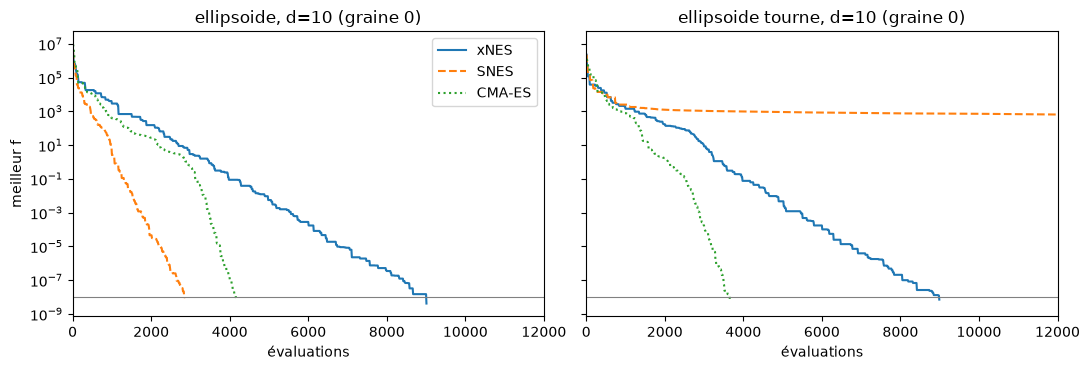

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, nom_f in zip(ax, ("ellipsoide", "ellipsoide tourne")):
    for nom_a, style in (("xNES", "-"), ("SNES", "--"), ("CMA-ES", ":")):
        t = traces[nom_f, nom_a]
        a.semilogy(t[:, 0], np.minimum.accumulate(t[:, 1]), style, label=nom_a)
    a.axhline(CIBLE, color="grey", lw=0.8)
    a.set_title(f"{nom_f}, d={D} (graine 0)"); a.set_xlabel("évaluations"); a.set_xlim(0, 12_000)
ax[0].set_ylabel("meilleur f"); ax[0].legend()
plt.tight_layout(); plt.show()

### Lecture du résultat

**Sur l'ellipsoïde séparable**, les trois méthodes atteignent la cible sur les quatre graines. SNES est le plus économe (médiane 2820 évaluations), devant CMA-ES (4235) et xNES (8850). C'est ce que le §5.3 annonce : sur un problème sans dépendance entre variables, la diagonale suffit, et elle s'apprend avec des pas bien plus grands.

**Sur l'ellipsoïde tourné**, le classement s'inverse :

- SNES **échoue sur les quatre graines**. Après 40 000 évaluations, son meilleur $f$ va jusqu'à $1{,}27\times10^{3}$. La figure montre un plateau atteint dès un millier d'évaluations : une gaussienne alignée sur les axes ne peut pas suivre une vallée oblique.
- xNES est **insensible à la rotation**, avec une médiane de 8935 évaluations contre 8850 sur le séparable (+1 %, dans le bruit des graines).
- CMA-ES reste aussi insensible, avec une médiane de 3850.

L'avantage de CMA-ES sur xNES, environ un facteur 2,3 en évaluations, est cohérent avec la comparaison de l'article : sur BBOB, xNES-as est moins bon que BIPOP-CMA-ES sur 18 fonctions et meilleur sur 6 (§5.2). Le §4 situe la différence : CMA-ES ajoute à la mise à jour rang-μ des **chemins d'évolution** (contrôle cumulatif du pas, mise à jour de rang 1) que xNES n'a pas. Ce carnet ne les isole pas ; c'est une hypothèse plausible, pas une mesure. Le banc est borné à $d=10$, à une seule matrice de rotation et à quatre graines.

## 5. Le lien avec CMA-ES (§4)

L'article montre que la mise à jour exponentielle de xNES, $\Sigma_{new} = A^\top \exp\!\big(\eta_\Sigma \sum_k u_k (s_k s_k^\top - I)\big) A$, coïncide **au premier ordre** avec la mise à jour « rang-μ » de CMA-ES, $(1-U\eta_\Sigma)\Sigma + \eta_\Sigma\sum_k u_k (z_k-\mu)(z_k-\mu)^\top$, où $U=\sum_k u_k$. Si c'est vrai, l'écart entre les deux doit décroître comme $\eta^2$ : le rapport $\lVert\Sigma_{xNES}-\Sigma_{rang\text{-}\mu}\rVert/\eta^2$ doit tendre vers une constante quand $\eta\to 0$. On le mesure sur une génération d'un tirage réel en dimension 5.

Une précision que l'article fait lui-même : avec les utilités de la table 1, $U=\sum_k u_k = 0$ (elles sont décalées pour sommer à zéro), alors que CMA-ES prend $U=1$. Le terme de décroissance $(1-U\eta)\Sigma$ n'est donc pas le même dans les deux algorithmes ; on teste ici la formule de l'article, avec le $U$ de xNES.

In [8]:
rng = np.random.default_rng(42)
d5 = 5; lam5 = reglages_table1(d5)[0]; u5 = utilites(lam5)
A = np.linalg.qr(rng.standard_normal((d5, d5)))[0] * np.linspace(0.5, 2.0, d5)
Sigma = A.T @ A
s = rng.standard_normal((lam5, d5))
fz = np.array([float(COND[:d5] @ (A.T @ v) ** 2) for v in s])
s = s[np.argsort(fz)]
G = sum(u5[k] * (np.outer(s[k], s[k]) - np.eye(d5)) for k in range(lam5))
U = u5.sum()
print(f"U = somme des utilites = {U:.1e}")
print(f"{'eta':>8} | {'||Sigma_xNES - Sigma_rang-mu||':>30} | {'rapport / eta^2':>15}")
for eta in (0.5, 0.1, 0.02, 0.004):
    s_xnes = A.T @ expm(eta * G) @ A
    s_rank = (1 - U * eta) * Sigma + eta * sum(u5[k] * np.outer(A.T @ s[k], A.T @ s[k]) for k in range(lam5))
    ecart = np.linalg.norm(s_xnes - s_rank)
    print(f"{eta:>8} | {ecart:>30.3e} | {ecart / eta ** 2:>15.4f}")
print(f"prediction du terme d'ordre 2, ||A^T G^2 A|| / 2 = {np.linalg.norm(A.T @ G @ G @ A) / 2:.4f}")

U = somme des utilites = -5.6e-17
     eta | ||Sigma_xNES - Sigma_rang-mu|| | rapport / eta^2
     0.5 |                      1.932e-01 |          0.7726
     0.1 |                      8.732e-03 |          0.8732
    0.02 |                      3.586e-04 |          0.8966
   0.004 |                      1.442e-05 |          0.9014
prediction du terme d'ordre 2, ||A^T G^2 A|| / 2 = 0.9026


### Lecture du résultat

L'écart entre les deux mises à jour décroît de $1{,}9\times10^{-1}$ à $1{,}4\times10^{-5}$ quand $\eta$ passe de 0,5 à 0,004. Rapporté à $\eta^2$, il vaut 0,773, puis 0,873, 0,897 et 0,901. Il converge vers la valeur 0,903 que prédit le terme d'ordre deux du développement de l'exponentielle, $\tfrac12\lVert A^\top G^2 A\rVert$. L'écart est donc bien en $O(\eta^2)$ : les deux mises à jour **coïncident au premier ordre**, comme l'affirme le §4.

Le premier ordre explique aussi pourquoi xNES et CMA-ES partagent l'invariance par rotation mesurée plus haut : leurs mises à jour de covariance ne diffèrent qu'à l'ordre deux. En revanche, il n'explique pas leur écart de vitesse, qui tient à ce que CMA-ES ajoute au rang-μ.

## 6. Bilan : ce que l'article affirme, ce que le carnet mesure

| Affirmation de l'article | Où | Mesure dans ce carnet |
|---|---|---|
| Le gradient simple ne sait pas localiser un optimum quadratique de façon stable | §2.2, fig. 1 | voir §2 |
| Le gradient naturel corrige ce défaut | §2.3 | voir §3.1 |
| La mise en forme rend l'algorithme invariant par transformation monotone de $f$ | §3.1 | voir §3.2 |
| xNES est invariant par rotation ; SNES est bon sur le séparable, mauvais sur le dépendant | §5.3, §6 | voir §4 |
| xNES-as est proche de BIPOP-CMA-ES, et moins bon sur une majorité de fonctions (18 contre 6) | §5.2 | voir §4 (xNES sans adaptation, CMA-ES de base) |
| La mise à jour xNES égale le rang-μ de CMA-ES au premier ordre | §4 | voir §5 |

Les lectures qui suivent chaque cellule de mesure donnent les chiffres ; la conclusion les rassemble.

## 7. Exercices

Les trois exercices réutilisent les fonctions `xnes`, `snes`, `utilites` et `lancer_cma` définies plus haut. Les cellules ne contiennent qu'une amorce : elles s'exécutent sans erreur tant qu'elles ne sont pas complétées.

### Exercice 1 — L'utilité est-elle un paramètre critique ?

Le §3.1 affirme que le choix de l'utilité « n'a pas été crucial », pourvu qu'elle soit monotone et fondée sur les rangs. Écrivez une utilité **linéaire en rang** (par exemple $u_k \propto \lambda+1-2k$, centrée et normalisée), passez-la à `xnes(..., utilite=...)`, et comparez le nombre d'évaluations sur `ellipsoide_tourne` avec l'utilité de la table 1, sur les quatre graines.

*Indice* : `xnes` accepte un argument `utilite`, une fonction qui prend `lam` et renvoie un tableau de longueur `lam`.

In [9]:
# Exercice 1 : utilite lineaire en rang
def utilite_lineaire(lam):
    # TODO etudiant : renvoyer un vecteur centre (somme nulle), decroissant avec le rang
    return None

print("Exercice a completer : definir utilite_lineaire puis comparer xnes(..., utilite=utilite_lineaire)")

Exercice a completer : definir utilite_lineaire puis comparer xnes(..., utilite=utilite_lineaire)


### Exercice 2 — Le prix de la covariance pleine

SNES coûte $O(d)$ par mise à jour, xNES $O(d^3)$ (exponentielle de matrice). Sur une sphère séparable $f(x)=\lVert x\rVert^2$, mesurez pour $d \in \{10, 40, 100\}$ le **temps de calcul** et le **nombre d'évaluations** des deux algorithmes jusqu'à $f\le 10^{-8}$. À partir de quelle dimension la différence de temps devient-elle gênante ? L'article fait cette observation sur le double pendule (fig. 8, à droite).

In [10]:
# Exercice 2 : xNES contre SNES quand la dimension croit
sphere = lambda x: float(x @ x)
dimensions = (10, 40, 100)
# TODO etudiant : pour chaque d, chronometrer xnes et snes depuis np.full(d, 3.0), sigma = 1
print("Exercice a completer : tableau d | evals xNES | temps xNES | evals SNES | temps SNES")

Exercice a completer : tableau d | evals xNES | temps xNES | evals SNES | temps SNES


### Exercice 3 — Un paysage courbe : Rosenbrock tourné

L'ellipsoïde est un paysage quadratique : une seule matrice de covariance bien réglée suffit. Le Rosenbrock suit une vallée **courbe**, que la distribution doit poursuivre. Implémentez $f(x)=\sum_{i=1}^{d-1} 100(x_{i+1}-x_i^2)^2 + (1-x_i)^2$ en dimension 10, appliquez la même rotation `R`, et comparez xNES, SNES et CMA-ES sur les quatre graines. L'écart entre xNES et CMA-ES est-il du même ordre que sur l'ellipsoïde tourné ?

In [11]:
# Exercice 3 : Rosenbrock tourne
def rosenbrock(x):
    # TODO etudiant : implementer la fonction de Rosenbrock (optimum f = 0 en x = 1)
    return 0.0

print("Exercice a completer : comparer xNES, SNES et CMA-ES sur x -> rosenbrock(R @ x)")

Exercice a completer : comparer xNES, SNES et CMA-ES sur x -> rosenbrock(R @ x)


## 8. Conclusion

Les six affirmations de l'article confrontées aux mesures de ce carnet :

| Affirmation | Mesure | Verdict |
|---|---|---|
| Le gradient simple ne localise pas un optimum quadratique de façon stable (§2.2) | 80 tirages sur 300 en échec après 1000 générations ; les survivants convergent lentement | reproduction **partielle** : instabilité confirmée, mais pas l'échec de convergence de la médiane |
| Le gradient naturel corrige ce défaut (§2.3) | 0 échec sur 300, une décade toutes les 10 générations, avec des pas 60 à 100 fois plus grands | confirmé |
| Invariance par transformation monotone (§3.1) | trajectoires xNES identiques à $3{,}4\times10^{-16}$ près ; le gradient simple, lui, change de trajectoire | confirmé |
| xNES invariant par rotation, SNES bon seulement sur le séparable (§5.3) | xNES 8850 / 8935 évaluations ; SNES 2820 puis 0/4 | confirmé |
| xNES moins bon que CMA-ES sur une majorité de fonctions (§5.2) | CMA-ES environ 2,3 fois plus rapide sur l'ellipsoïde tourné | cohérent, sur une seule fonction |
| Équivalence au premier ordre avec le rang-μ de CMA-ES (§4) | écart / $\eta^2$ convergeant vers 0,903 | confirmé |

Trois idées à retenir :

1. **On optimise une distribution, pas un point.** Le gradient de $\mathbb{E}[f]$ s'estime sur des échantillons, sans dérivée de $f$.
2. **La géométrie de la distribution compte.** Mesurer les pas en divergence KL plutôt qu'en distance euclidienne transforme une méthode instable en une méthode qui converge à vitesse géométrique.
3. **La forme de la covariance est un compromis.** La covariance pleine coûte $O(d^3)$ par génération et apprend lentement, mais résiste aux rotations. La diagonale est rapide et passe à l'échelle, mais échoue dès que les variables sont liées.

**L'organe du dépôt.** Ce carnet réécrit xNES et SNES en quelques lignes de numpy, pour les montrer. L'implémentation de référence du dépôt est le composé C# `NaturalEvolutionStrategy` de [MetaGeneticSharp](../MetaGeneticSharp/), qui propose les deux modèles de covariance (pleine et diagonale). Ses tests vérifient l'**équivariance exacte** de xNES par rotation, avec SNES comme contre-témoin, et comparent les deux bras sur Rosenbrock non tourné puis tourné, sur les mêmes graines {0, 1, 7, 42} (règle de verdict préenregistrée sur l'issue #13778). C'est une vérification indépendante de celle de la section 4 : autre langage, autre paysage, même conclusion attendue.

Pour aller plus loin, on peut ajouter à xNES la **taille de population adaptative** et l'**échantillonnage d'adaptation** (§5.2, xNES-as), ou passer à CMA-ES, dont le carnet a montré la parenté au premier ordre.

**Référence** : D. Wierstra *et al.*, « Natural Evolution Strategies », *JMLR* 15 (2014) 949-980. Copie : `G:\Mon Drive\MyIA\IA\Bibliographie IA\MachineLearning\2014 - Wierstra et al - Natural Evolution Strategies.pdf` (sha256 préfixe `80ec8495`).